### First of all I imported my libraries and impoted data into jupyter lab 

In [8]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
sales = pd.read_csv("../data/raw/m5-forecasting-accuracy\sales_train_validation.csv")
calendar = pd.read_csv("../data/raw/m5-forecasting-accuracy/calendar.csv")
prices = pd.read_csv("../data/raw/m5-forecasting-accuracy/sell_prices.csv")

print("sales shape:", sales.shape)
print("Calendar shape:", calendar.shape)
print("Prices shape:", prices.shape)

sales shape: (30490, 1919)
Calendar shape: (1969, 14)
Prices shape: (6841121, 4)


### then I just observed sales column 

In [9]:
print("First 10 columns:")
print(sales.columns[:10].tolist())

print("\nLast 10 columns:")
print(sales.columns[-10:].tolist())

print("\nDataset information:")
sales.info()

First 10 columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4']

Last 10 columns:
['d_1904', 'd_1905', 'd_1906', 'd_1907', 'd_1908', 'd_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1919 entries, id to d_1913
dtypes: int64(1913), object(6)
memory usage: 446.4+ MB


### Then I observed and tried to understand daily_sales

In [17]:
sales_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]
# In our sales table , every day column starts with day 
print("Number of daily sales columns:", len(sales_columns))

print("\nSales statistics:")
print(sales[sales_columns].describe())

Number of daily sales columns: 1913

Sales statistics:
                d_1           d_2           d_3           d_4           d_5  \
count  30490.000000  30490.000000  30490.000000  30490.000000  30490.000000   
mean       1.070220      1.041292      0.780026      0.833454      0.627944   
std        5.126689      5.365468      3.667454      4.415141      3.379344   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.000000      0.000000      0.000000      0.000000      0.000000   
max      360.000000    436.000000    207.000000    323.000000    296.000000   

                d_6           d_7           d_8           d_9          d_10  \
count  30490.000000  30490.000000  30490.000000  30490.000000  30490.000000   
mean       0.958052      0.918662      1.244080      1.073663      0.838701

### tried to understand the pattern of sales 

In [23]:
# Total units sold across all days
total_sales = sales[sales_columns].sum().sum()

# Average daily sales per product-store combination
average_sales = sales[sales_columns].values.mean()

# Percentage of zero-sales observations
zero_sales_percentage = (
    (sales[sales_columns] == 0).sum().sum()
    / sales[sales_columns].size
) * 100

print("Total units sold:", total_sales)
print("Average daily sales:", round(average_sales, 2))
print("Zero-sales percentage:", round(zero_sales_percentage, 2), "%")

Total units sold: 65695409
Average daily sales: 1.13
Zero-sales percentage: 68.2 %


### TO UNDERSTAND THE SCALE OF OUR RETAIL BUSINESS

In [24]:
print("Total records:", len(sales))
print("Unique products:", sales["item_id"].nunique())
print("Unique departments:", sales["dept_id"].nunique())
print("Unique categories:", sales["cat_id"].nunique())
print("Unique stores:", sales["store_id"].nunique())
print("Unique states:", sales["state_id"].nunique())

Total records: 30490
Unique products: 3049
Unique departments: 7
Unique categories: 3
Unique stores: 10
Unique states: 3


In [25]:
print("Missing values in sales:", sales.isnull().sum().sum())
print("Missing values in calendar:", calendar.isnull().sum().sum())
print("Missing values in prices:", prices.isnull().sum().sum())

Missing values in sales: 0
Missing values in calendar: 7542
Missing values in prices: 0


In [26]:
sales_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

daily_totals = sales[sales_columns].sum()

print("Total units sold:", daily_totals.sum())
print("Average total sales per day:", round(daily_totals.mean(), 2))
print("Highest daily sales:", daily_totals.max())
print("Lowest daily sales:", daily_totals.min())

Total units sold: 65695409
Average total sales per day: 34341.56
Highest daily sales: 57218
Lowest daily sales: 11


### Visualizing the daily overall sales data for better understanding 

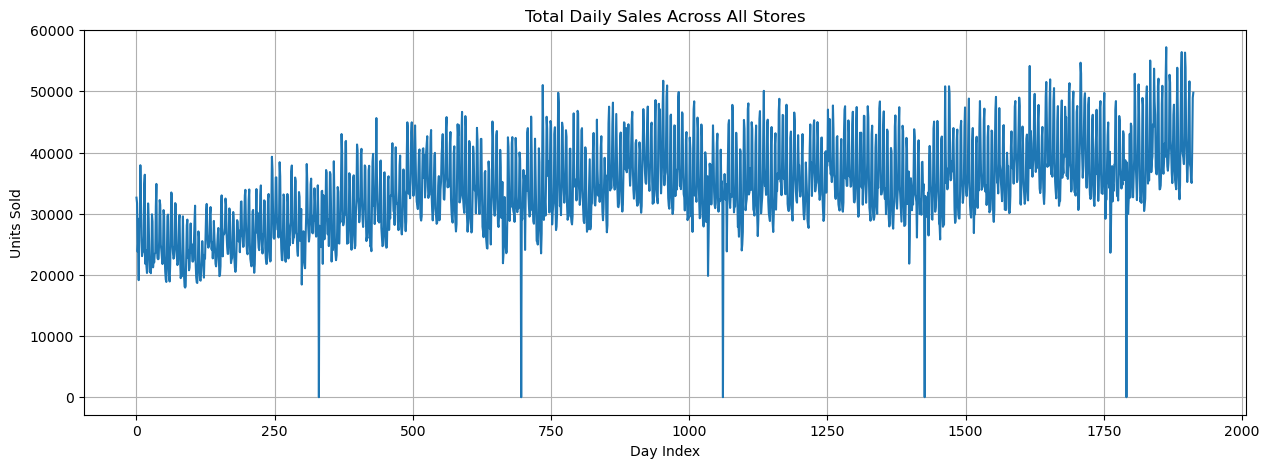

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(daily_totals.values)
plt.title("Total Daily Sales Across All Stores")
plt.xlabel("Day Index")
plt.ylabel("Units Sold")
plt.grid(True)
plt.show()

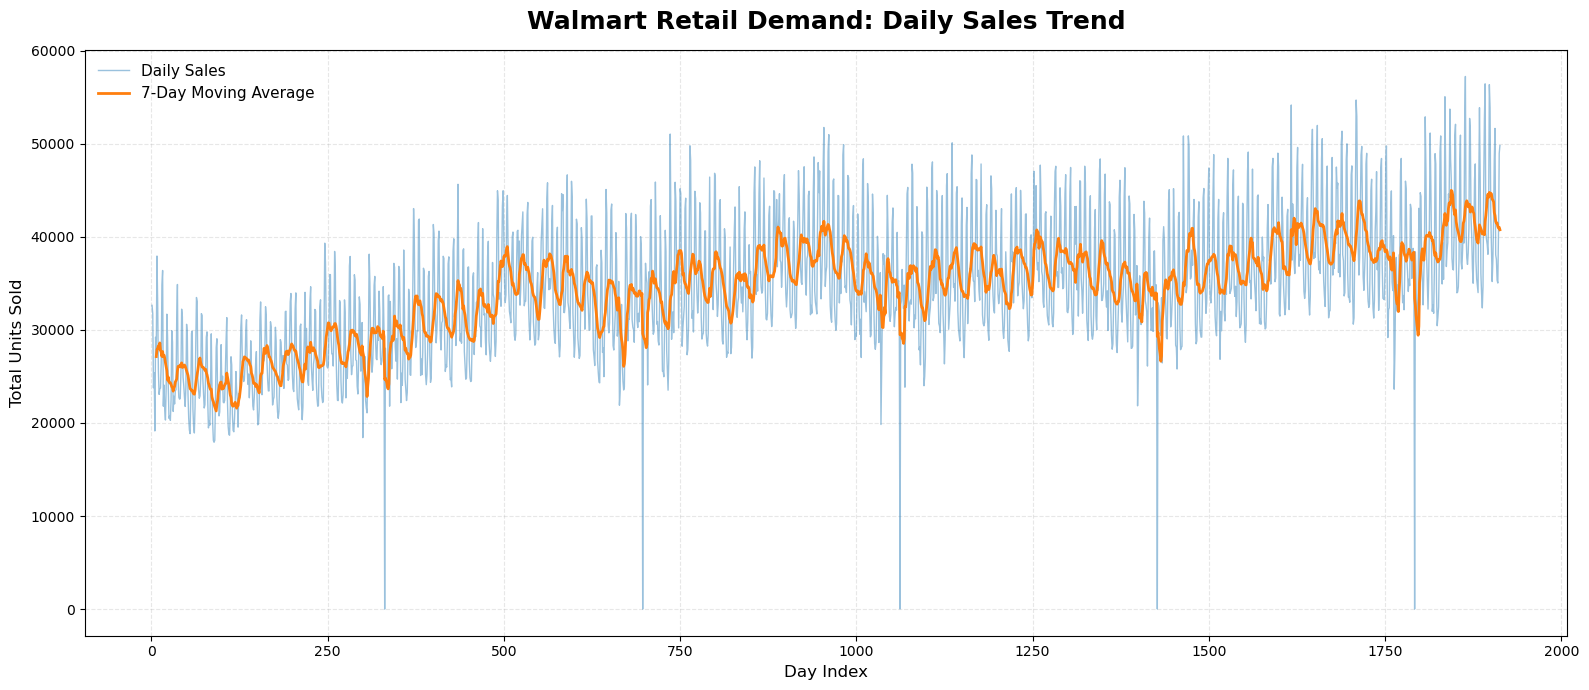

In [28]:

# Calculate total sales across all products and stores per day
daily_totals = sales[sales_columns].sum()

# Convert daily sales into a time series
daily_sales = pd.DataFrame({
    "Day": range(1, len(daily_totals) + 1),
    "Units Sold": daily_totals.values
})

# Calculate 7-day moving average
daily_sales["7-Day Moving Average"] = (
    daily_sales["Units Sold"].rolling(window=7).mean()
)

# Create the graph
fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    daily_sales["Day"],
    daily_sales["Units Sold"],
    label="Daily Sales",
    alpha=0.45,
    linewidth=1
)

ax.plot(
    daily_sales["Day"],
    daily_sales["7-Day Moving Average"],
    label="7-Day Moving Average",
    linewidth=2
)

ax.set_title(
    "Walmart Retail Demand: Daily Sales Trend",
    fontsize=18,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Day Index", fontsize=12)
ax.set_ylabel("Total Units Sold", fontsize=12)

ax.legend(frameon=False, fontsize=11)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()